# 03 · Null handling & feature engineering (leak-free)

All experiments use the **leak-free** feature set: the 9 day-counter columns are excluded (EDA section 8,
notebook 02 section 7: they record the bank freezing the account, not mule behaviour).

**Protocol.** Every variant is trained with the *baseline model unchanged* (XGBoost, class weight ×49, default params),
so only the **data** changes. Each variant runs with **3 CV seeds** (different fold splits and model seeds) and we report
mean ± std, so a gain is believed only if it is larger than the seed-to-seed noise. Scores are Platt-calibrated
on OOF predictions (notebook 02). Primary metrics: **OOF PR-AUC** and **OOF log-loss** on the 80k dev set (1,600 mules,
more stable than the 400-mule holdout); holdout shown alongside.

**Selection rule (used throughout):** a variant *ties* with the best if its OOF log-loss is within the seed-to-seed noise
(the larger of the two variants' standard deviations). Among tied variants take the **simplest**. A gain smaller
than the noise is not worth extra moving parts.

Plan:
1. **Cleaning** that is not a modelling choice (constants, sentinel, mixed types, ordinals, dates).
2. **Null handling**: native NaN vs missing flags vs zero-fill vs median vs **KNN imputation**.
3. **Feature engineering**: transaction aggregates & velocity, short/long-window ratios.

In [1]:
import sys; sys.path.insert(0, '..')
from time import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, confusion_matrix
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from src.data import DataLoader, ID, TARGET
from src.model import XGBCV, PlattCalibrator, evaluate

BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.titleweight': 'bold', 'axes.titlesize': 11})
pd.set_option('display.float_format', '{:.4f}'.format, 'display.width', 200)

train = DataLoader().load('train')
y = train[TARGET]
idx_dev, idx_hold = train_test_split(train.index, test_size=.2, stratify=y, random_state=42)   # same split as notebook 02
y_dev, y_hold = y.loc[idx_dev], y.loc[idx_hold]

## 0. Experiment harness

In [2]:
RESULTS, PREDS = {}, {}

def within_noise(a, b):
    """True if a's OOF log-loss is within the seed-to-seed noise (larger of the two stds) of b's."""
    return a.oof_log_loss - b.oof_log_loss <= max(a.oof_log_loss_std, b.oof_log_loss_std)

def f1_threshold(y_true, p):
    """Threshold that maximises F1 (chosen on OOF predictions, then applied to the holdout)."""
    pr, rc, thr = precision_recall_curve(y_true, p)
    return thr[np.argmax(2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12))]

def plot_confusions(names, ncols=4):
    """Holdout confusion matrix (last seed) of each experiment at its OOF-F1-optimal threshold."""
    nrows = -(-len(names) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.2 * nrows), squeeze=False)
    for ax, n in zip(axes.flat, names):
        p, t = PREDS[n]
        cm = confusion_matrix(y_hold, p >= t)
        ax.imshow(cm, cmap='Blues', norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=len(y_hold))); ax.grid(False)
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, f'{v:,}', ha='center', va='center', fontsize=11, color='white' if v > 1000 else 'black')
        tn, fp, fn, tp = cm.ravel()
        ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['pred legit', 'pred mule'], yticklabels=['legit', 'mule'])
        ax.set_title(f'{n}\nP={tp / max(tp + fp, 1):.3f} R={tp / (tp + fn):.3f} @t={t:.2f}', fontsize=9)
    for ax in axes.flat[len(names):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()

def run(name, X, seeds=(0, 1, 2)):
    """3 x (5-fold CV on dev) -> Platt on OOF -> metrics on OOF and holdout. Returns the last fitted CV model."""
    t, rows = time(), []
    Xd, Xh = X.loc[idx_dev], X.loc[idx_hold]
    for s in seeds:
        cv = XGBCV(seed=s).fit(Xd, y_dev)
        cal = PlattCalibrator().fit(cv.oof_, y_dev)
        rows.append({**{f'oof_{k}': v for k, v in evaluate(y_dev, cal.predict(cv.oof_)).items()},
                     **{f'hold_{k}': v for k, v in evaluate(y_hold, cal.predict(cv.predict_proba(Xh))).items()}})
    PREDS[name] = (cal.predict(cv.predict_proba(Xh)), f1_threshold(y_dev, cal.predict(cv.oof_)))
    r = pd.DataFrame(rows)
    RESULTS[name] = pd.concat([r.mean().add_suffix(''), r.std().add_suffix('_std')])
    m = RESULTS[name]
    print(f'{name:<38} {X.shape[1]:>4} feats | OOF PR-AUC {m.oof_pr_auc:.4f}±{m.oof_pr_auc_std:.4f}  '
          f'log-loss {m.oof_log_loss:.5f}±{m.oof_log_loss_std:.5f} | holdout PR-AUC {m.hold_pr_auc:.4f} log-loss {m.hold_log_loss:.5f} | {time() - t:.0f}s')
    return cv

COUNTERS = ['others_6', 'others_7', 'others_9', 'others_10', 'others_12', 'others_13', 'others_15', 'others_16', 'demog_23']

def to_raw(df):
    """Notebook 02's minimal encoding, counters removed (= the leak-free baseline)."""
    X = df.drop(columns=[ID, TARGET, *COUNTERS], errors='ignore')
    X['account_opening_date'] = X.account_opening_date.astype('int64') // 86_400_000_000
    for c in X.select_dtypes(exclude='number').columns:
        X[c] = X[c].astype('category')
    return X

_ = run('A. raw, leak-free (baseline)', to_raw(train))

A. raw, leak-free (baseline)            167 feats | OOF PR-AUC 0.9177±0.0003  log-loss 0.01710±0.00009 | holdout PR-AUC 0.9306 log-loss 0.01615 | 27s


## 1. Cleaning
* **Constant columns** (12) carry no information → dropped (list learned from the development data).
* **`others_27/28 = 9999`** is a "not applicable" code → NaN, so it is not read as a huge number.
* **Ordered categories → ordinals**: `income` bands, `city_tier` (Tier 1 … Tier 8, Rural), `demog_40/43` (low < medium < High).
  `demog_22` Y/N → 1/0.
* **Unordered codes → `category`**: `demog_2` (has `'ZZ'`), `demog_4` (has `'N'`), `country_code`, `occupation`, `os`, `email_domain`.
* **Dates**: the raw date becomes **account age at the snapshot** (2023-08-05, found in the EDA) plus opening weekday.
  Trees cannot use a timestamp meaningfully; "how old is the account" is the quantity a monitor would actually know.

In [3]:
SNAPSHOT = pd.Timestamp('2023-08-05')
CONSTANT = [c for c in train.columns if train[c].nunique() <= 1]
INCOME = ['0', '0 to 1L', '100001 to 5L', '5L to 10L', '10L to 25L', '25L to 50L', '50L to 3Crore', '3Crore to 5Crore',
          '5Crore to 10Crore', '10Crore to 15Crore', '15Crore to 20Crore', '20Crore to 35Crore']
ORDINAL = {'income': {v: i for i, v in enumerate(INCOME)},
           'city_tier': {**{f'Tier {i}': i for i in range(1, 9)}, 'Rural': 9},
           'demog_40': {'low': 0, 'medium': 1, 'High': 2}, 'demog_43': {'low': 0, 'medium': 1, 'High': 2},
           'demog_22': {'N': 0, 'Y': 1}}
CATEGORICAL = ['demog_2', 'demog_4', 'country_code', 'occupation', 'os', 'email_domain']
print('constant columns dropped:', CONSTANT)

def clean(df):
    X = df.drop(columns=[ID, TARGET, *CONSTANT, *COUNTERS], errors='ignore')
    X[['others_27', 'others_28']] = X[['others_27', 'others_28']].replace(9999, np.nan)
    for c, m in ORDINAL.items():
        X[c] = X[c].map(m).astype(float)
    for c in CATEGORICAL:
        X[c] = X[c].astype('category')
    X['account_age'] = (SNAPSHOT - X.account_opening_date).dt.days
    X['open_dow'] = X.account_opening_date.dt.dayofweek
    return X.drop(columns='account_opening_date')

X_clean = clean(train)
_ = run('B. clean, NaN left to XGBoost', X_clean)

constant columns dropped: ['demog_7', 'demog_10', 'demog_12', 'txn_35', 'txn_36', 'txn_49', 'txn_50', 'txn_65', 'txn_70', 'txn_71', 'txn_72', 'demog_38']


B. clean, NaN left to XGBoost           156 feats | OOF PR-AUC 0.9270±0.0021  log-loss 0.01575±0.00027 | holdout PR-AUC 0.9395 log-loss 0.01476 | 49s


## 2. Null-handling strategies
Missing **blocks** from the EDA: txn block (76 cols), `txn_77–81`, logins `others_21–26`, `others_15–17`, `others_5`,
`os`, `demog_9`, the country/demog block, `demog_13–16`, `demog_24/26`. Strategies:
Gradient-boosted trees handle NaN natively, but that is a modelling choice to *test*, not to assume:
* **B (above)**: keep NaN, XGBoost learns at every split which side missing rows should go (the direction with the larger loss reduction).
* **C**: B + one flag per missing block + row-level missing count.
* **D**: "missing = none": counts (txn, logins, others) → 0, categoricals → most frequent, everything else → median.
* **E**: classic median / most-frequent imputation of everything.
* **E2**: **KNN imputation**: each missing value = mean of that feature over the 5 most similar accounts
  (nan-Euclidean distance on standardised numeric features). Donors = 20k random dev rows (all 80k would take ~45 min;
  every row has at least one NaN because of the >95%-empty `others_42–45`). Categoricals → most frequent.

In [4]:
BLOCKS = {'txn_block': 'txn_1', 'txn_77': 'txn_77', 'txn_78': 'txn_78', 'txn_80': 'txn_80', 'txn_81': 'txn_81',
          'logins_block': 'others_21', 'others_15_block': 'others_15', 'others_5': 'others_5', 'os': 'os',
          'demog_9': 'demog_9', 'country_block': 'country_code', 'demog_13_block': 'demog_13', 'age_block': 'demog_24',
          'demog_4': 'demog_4'}

def add_missing_flags(X, df):
    X = X.copy()
    for name, col in BLOCKS.items():
        X[f'na_{name}'] = df[col].isna().astype(int)
    X['n_missing'] = df.drop(columns=[ID, TARGET], errors='ignore').isna().sum(axis=1)
    return X

def impute(X, zero_counts):
    X = X.copy()
    num = X.select_dtypes('number').columns
    counts = [c for c in num if c.startswith('txn_') or c.startswith('others_')] if zero_counts else []
    X[counts] = X[counts].fillna(0)
    rest = num.difference(counts)
    X[rest] = X[rest].fillna(X.loc[idx_dev, rest].median())          # statistics from dev rows only
    for c in X.select_dtypes('category').columns:
        X[c] = X[c].fillna(X.loc[idx_dev, c].mode()[0])
    return X

def knn_impute(X, k=5, n_donors=20_000):
    X = X.copy()
    num = X.select_dtypes('number').columns
    donors = pd.Series(idx_dev).sample(n_donors, random_state=0)          # dev rows only: holdout never informs imputation
    scaler = StandardScaler().fit(X.loc[idx_dev, num])                     # NaN-aware: ignored in fit, kept in transform
    knn = KNNImputer(n_neighbors=k, keep_empty_features=True).fit(scaler.transform(X.loc[donors, num]))
    X[num] = scaler.inverse_transform(knn.transform(scaler.transform(X[num])))
    for c in X.select_dtypes('category').columns:
        X[c] = X[c].fillna(X.loc[idx_dev, c].mode()[0])
    return X

t = time()
X_knn = knn_impute(X_clean)
print(f'KNN imputation: {(time() - t) / 60:.1f} min, NaN left: {int(X_knn.isna().sum().sum())}')

NULL_VARIANTS = {'B. clean, NaN left to XGBoost': X_clean,
                 'C. clean + missing flags': add_missing_flags(X_clean, train),
                 'D. fill 0 for counts, median rest': impute(X_clean, zero_counts=True),
                 'E. median / mode everything': impute(X_clean, zero_counts=False),
                 'E2. KNN imputation (k=5)': X_knn}
for name in list(NULL_VARIANTS)[1:]:
    _ = run(name, NULL_VARIANTS[name])

KNN imputation: 9.7 min, NaN left: 0


C. clean + missing flags                171 feats | OOF PR-AUC 0.9266±0.0023  log-loss 0.01578±0.00032 | holdout PR-AUC 0.9396 log-loss 0.01469 | 39s


D. fill 0 for counts, median rest       156 feats | OOF PR-AUC 0.9225±0.0019  log-loss 0.01654±0.00020 | holdout PR-AUC 0.9319 log-loss 0.01578 | 24s


E. median / mode everything             156 feats | OOF PR-AUC 0.9227±0.0010  log-loss 0.01648±0.00017 | holdout PR-AUC 0.9280 log-loss 0.01626 | 22s


E2. KNN imputation (k=5)                156 feats | OOF PR-AUC 0.9132±0.0006  log-loss 0.01804±0.00012 | holdout PR-AUC 0.9216 log-loss 0.01737 | 24s


In [5]:
# variants are listed simplest-first; take the first one that ties with the best (within_noise)
best = min(NULL_VARIANTS, key=lambda n: RESULTS[n].oof_log_loss)
NULL_WINNER = next(n for n in NULL_VARIANTS if within_noise(RESULTS[n], RESULTS[best]))
print(f'best = {best}; simplest tied with it = {NULL_WINNER}  -> carried forward')
base_null = NULL_VARIANTS[NULL_WINNER]

best = B. clean, NaN left to XGBoost; simplest tied with it = B. clean, NaN left to XGBoost  -> carried forward


**Null handling: conclusions**

| Result | Why it happens | Decision |
|---|---|---|
| **Cleaning is the biggest gain here** (A → B): OOF log-loss 0.0171 → 0.0158 (−8%, ~5× the seed noise), PR-AUC 0.918 → 0.927 | ordinal encodings let one split separate ordered risk tiers (`demog_40` low/medium/High); the `9999` code no longer looks like a huge value; 11 constant columns gone | keep all cleaning steps |
| **Native NaN (B) ≈ missing flags (C)** | XGBoost already learns a direction for missing values at every split, which *is* a missing flag | flags are redundant → not used |
| **Every imputation hurts**: zero-fill +5%, median +5%, **KNN +15%** (worse than no cleaning) | missingness *is* information: a missing transaction block means a dormant account (0.5% mules vs 2.5% when present). Imputation overwrites "no record" with a plausible number. KNN is worst because it copies the *activity of similar customers* into dormant accounts, making them look active, which is closer to mule behaviour (and it took 10 min) | **keep NaN (B)** |

## 3. Feature engineering
EDA findings that motivate each feature family:
* **Aggregates & velocity.** Mules move far more money than legit customers (`txn_5`, `txn_11`, `txn_75` are 70–140×
  the legit mean). A single "how much activity in total" number (`txn_sum`, `txn_nonzero`, `txn_max`) and
  **activity per day of account age** (`*_per_day`: a 30-day-old account with 400 transactions is very different from
  a 240-day-old one) summarise this in a way one tree split can use.
* **Short / long window ratios.** Consecutive `txn` pairs are nested windows (`txn_odd ≤ txn_even` in 100% of rows for 28
  pairs), and so are the login-like `others_21–26`. `odd / even` = **share of activity that is recent** (burst
  behaviour: receive, forward, disappear). Defined as 0 when the long window is 0, NaN when unknown.

Each family is tested alone and together on top of the null-handling winner.

In [6]:
NESTED = [(a, a + 1) for a in range(1, 77, 2) if train[f'txn_{a}'].nunique() > 1
          and (train[f'txn_{a + 1}'] >= train[f'txn_{a}'])[train[f'txn_{a}'].notna()].mean() > .98]
TXN_BLOCK = [c for c in train.columns if c.startswith('txn_') and int(c[4:]) <= 76 and c not in CONSTANT]
print(f'{len(NESTED)} nested txn pairs used for ratios')

def ratio(a, b):
    return (a / b).where(b != 0, 0)          # 0 when the long window is empty, NaN stays NaN

def add_txn_aggregates(X):
    X = X.copy()
    blk = X[TXN_BLOCK]
    X['txn_sum'] = blk.sum(axis=1, min_count=1)
    X['txn_nonzero'] = (blk > 0).sum(axis=1).where(blk.notna().any(axis=1))
    X['txn_max'] = blk.max(axis=1)
    age = X.account_age.clip(lower=1)
    X['txn_per_day'] = X.txn_sum / age
    for c in ['txn_5', 'txn_6', 'txn_11', 'txn_12', 'txn_75', 'txn_76', 'others_25', 'others_26']:
        X[f'{c}_per_day'] = X[c] / age
    return X

def add_window_ratios(X):
    X = X.copy()
    for a, b in NESTED:
        X[f'r_txn_{a}_{b}'] = ratio(X[f'txn_{a}'], X[f'txn_{b}'])
    for a, b in [(21, 22), (23, 24), (25, 26)]:
        X[f'r_oth_{a}_{b}'] = ratio(X[f'others_{a}'], X[f'others_{b}'])
    return X

FE_VARIANTS = {'F. + txn aggregates & velocity': add_txn_aggregates(base_null),
               'G. + window ratios': add_window_ratios(base_null)}
FE_VARIANTS['H. + aggregates + ratios'] = add_window_ratios(FE_VARIANTS['F. + txn aggregates & velocity'])
CVS = {name: run(name, X) for name, X in FE_VARIANTS.items()}
FE_CANDIDATES = {'B/null winner (no FE)': base_null, **FE_VARIANTS}
RESULTS['B/null winner (no FE)'] = RESULTS[NULL_WINNER]
best = min(FE_CANDIDATES, key=lambda n: RESULTS[n].oof_log_loss)
FE_WINNER = next(n for n in FE_CANDIDATES if within_noise(RESULTS[n], RESULTS[best]))
del RESULTS['B/null winner (no FE)']
print(f'best = {best}; simplest tied with it = {FE_WINNER}  -> carried forward')

32 nested txn pairs used for ratios


F. + txn aggregates & velocity          168 feats | OOF PR-AUC 0.9266±0.0031  log-loss 0.01585±0.00046 | holdout PR-AUC 0.9387 log-loss 0.01485 | 38s


G. + window ratios                      191 feats | OOF PR-AUC 0.9287±0.0007  log-loss 0.01570±0.00007 | holdout PR-AUC 0.9338 log-loss 0.01573 | 40s


H. + aggregates + ratios                203 feats | OOF PR-AUC 0.9283±0.0004  log-loss 0.01560±0.00006 | holdout PR-AUC 0.9347 log-loss 0.01559 | 42s
best = H. + aggregates + ratios; simplest tied with it = B/null winner (no FE)  -> carried forward


### 3c. Feature selection: prune features the model never uses
Features with zero gain in every fold of the winning model add nothing; dropping them shrinks the model and removes noise.

In [7]:
X_full = FE_CANDIDATES[FE_WINNER]
cv_w = CVS.get(FE_WINNER) or XGBCV(seed=2).fit(X_full.loc[idx_dev], y_dev)   # no-FE winner: fit once for importances
imp = cv_w.feature_importance('gain').reindex(X_full.columns).fillna(0)
unused = imp[imp == 0].index.tolist()
print(f'{len(unused)} features with zero gain:', unused)
X_sel = X_full.drop(columns=unused)
_ = run('J. winner, zero-gain features pruned', X_sel)

39 features with zero gain: ['demog_6', 'demog_11', 'demog_17', 'demog_19', 'demog_22', 'txn_15', 'txn_16', 'txn_21', 'txn_27', 'txn_37', 'txn_45', 'txn_47', 'txn_48', 'txn_55', 'txn_56', 'txn_61', 'txn_62', 'txn_64', 'txn_66', 'txn_67', 'others_20', 'others_29', 'demog_25', 'demog_27', 'demog_29', 'demog_31', 'demog_34', 'demog_35', 'demog_36', 'demog_37', 'others_33', 'others_38', 'others_40', 'others_41', 'demog_39', 'demog_41', 'others_44', 'others_45', 'demog_42']


J. winner, zero-gain features pruned    117 feats | OOF PR-AUC 0.9271±0.0022  log-loss 0.01576±0.00027 | holdout PR-AUC 0.9395 log-loss 0.01475 | 24s


## 4. Results

In [8]:
res = pd.DataFrame(RESULTS).T
cols = ['oof_pr_auc', 'oof_pr_auc_std', 'oof_log_loss', 'oof_log_loss_std', 'oof_brier', 'oof_roc_auc', 'hold_pr_auc', 'hold_log_loss', 'hold_brier', 'hold_roc_auc']
res[cols]

,oof_pr_auc,oof_pr_auc_std,oof_log_loss,oof_log_loss_std,oof_brier,oof_roc_auc,hold_pr_auc,hold_log_loss,hold_brier,hold_roc_auc
"A. raw, leak-free (baseline)",0.9177,0.0003,0.0171,0.0001,0.0040,0.9929,0.9306,0.0161,0.0038,0.9936
"B. clean, NaN left to XGBoost",0.9270,0.0021,0.0158,0.0003,0.0039,0.9949,0.9395,0.0148,0.0036,0.9953
C. clean + missing flags,0.9266,0.0023,0.0158,0.0003,0.0039,0.9948,0.9396,0.0147,0.0036,0.9953
"D. fill 0 for counts, median rest",0.9225,0.0019,0.0165,0.0002,0.0041,0.9944,0.9319,0.0158,0.0040,0.9959
E. median / mode everything,0.9227,0.0010,0.0165,0.0002,0.0041,0.9944,0.9280,0.0163,0.0040,0.9943
E2. KNN imputation (k=5),0.9132,0.0006,0.0180,0.0001,0.0044,0.9929,0.9216,0.0174,0.0042,0.9928
F. + txn aggregates & velocity,0.9266,0.0031,0.0158,0.0005,0.0039,0.9947,0.9387,0.0149,0.0037,0.9956
G. + window ratios,0.9287,0.0007,0.0157,0.0001,0.0039,0.9950,0.9338,0.0157,0.0040,0.9952
H. + aggregates + ratios,0.9283,0.0004,0.0156,0.0001,0.0039,0.9952,0.9347,0.0156,0.0039,0.9954
"J. winner, zero-gain features pruned",0.9271,0.0022,0.0158,0.0003,0.0039,0.9949,0.9395,0.0148,0.0036,0.9953


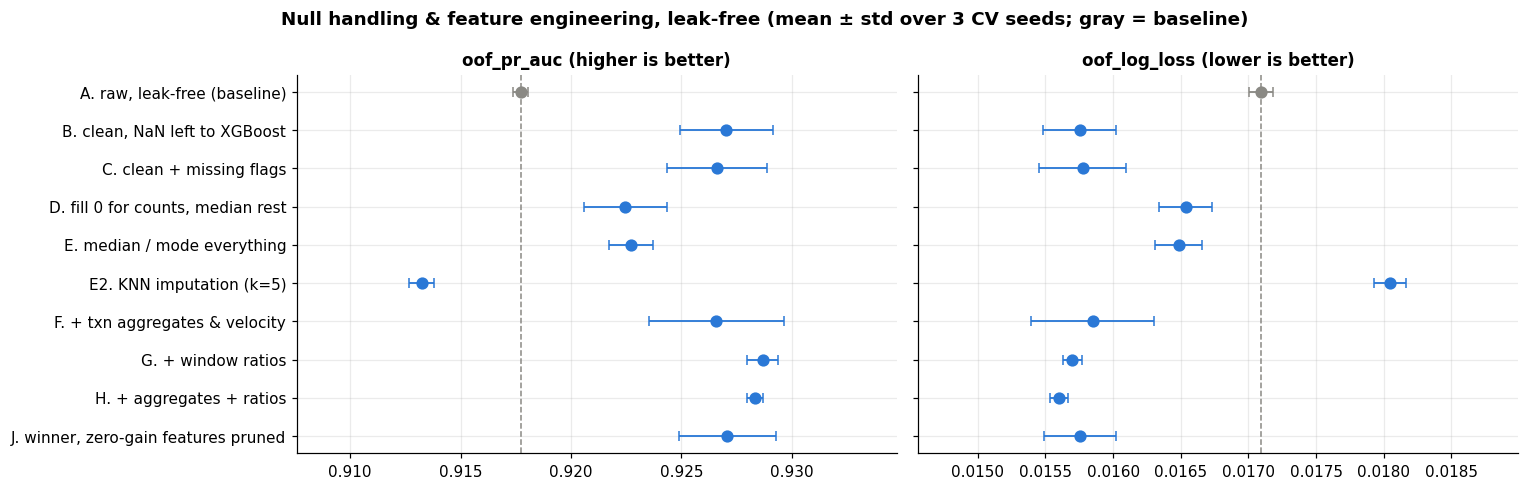

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, m, better in zip(axes, ['oof_pr_auc', 'oof_log_loss'], ['higher', 'lower']):
    for i, n in enumerate(res.index[::-1]):
        ax.errorbar(res.loc[n, m], i, xerr=res.loc[n, f'{m}_std'], fmt='o', ms=7, capsize=3, lw=1.2,
                    color=GRAY if n.startswith('A.') else BLUE)
    ax.set_yticks(range(len(res)), res.index[::-1])
    lo, hi = (res[m] - res[f'{m}_std']).min(), (res[m] + res[f'{m}_std']).max()
    ax.set(xlim=(lo - (hi - lo) * .3, hi + (hi - lo) * .3), title=f'{m} ({better} is better)')
    ax.axvline(res.loc['A. raw, leak-free (baseline)', m], color=GRAY, ls='--', lw=1)
axes[1].tick_params(axis='y', labelleft=False)
plt.suptitle('Null handling & feature engineering, leak-free (mean ± std over 3 CV seeds; gray = baseline)', fontweight='bold'); plt.tight_layout(); plt.show()

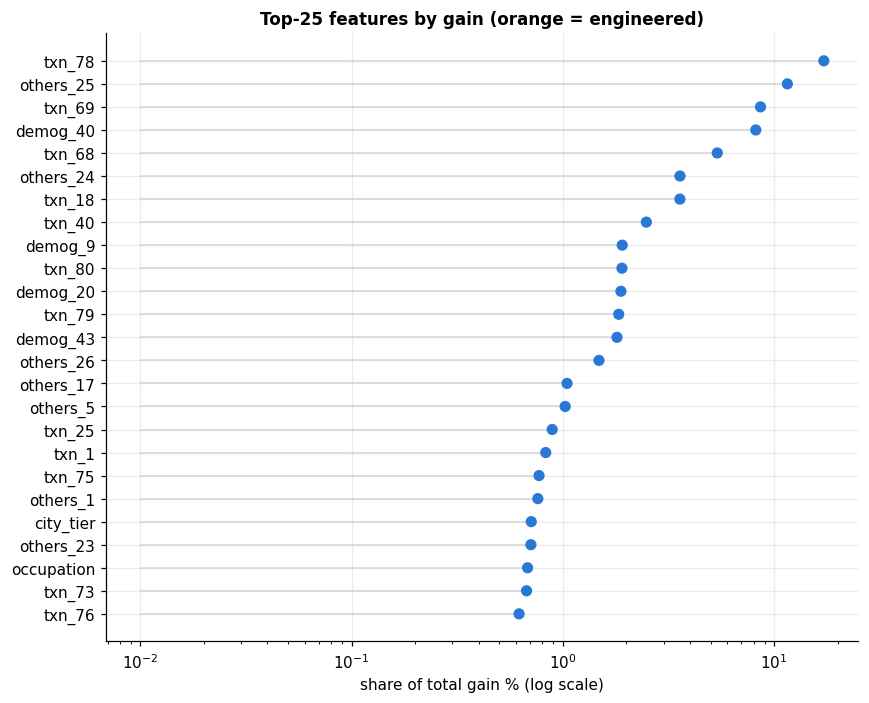

In [10]:
imp_sel = imp.drop(unused).sort_values(ascending=False)
top = imp_sel.head(25)[::-1]
new = set(X_full.columns) - set(X_clean.columns)
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.hlines(top.index, 1e-2, top.values / imp_sel.sum() * 100, color='#d6d5d0', lw=1)
ax.scatter(top.values / imp_sel.sum() * 100, top.index, color=[ORANGE if c in new else BLUE for c in top.index], s=40, zorder=3)
ax.set(xlabel='share of total gain % (log scale)', xscale='log', title='Top-25 features by gain (orange = engineered)')
plt.tight_layout(); plt.show()

### Confusion matrices — every experiment
Holdout (20k accounts, 400 mules), last seed, threshold = F1-optimal on that experiment's OOF predictions.

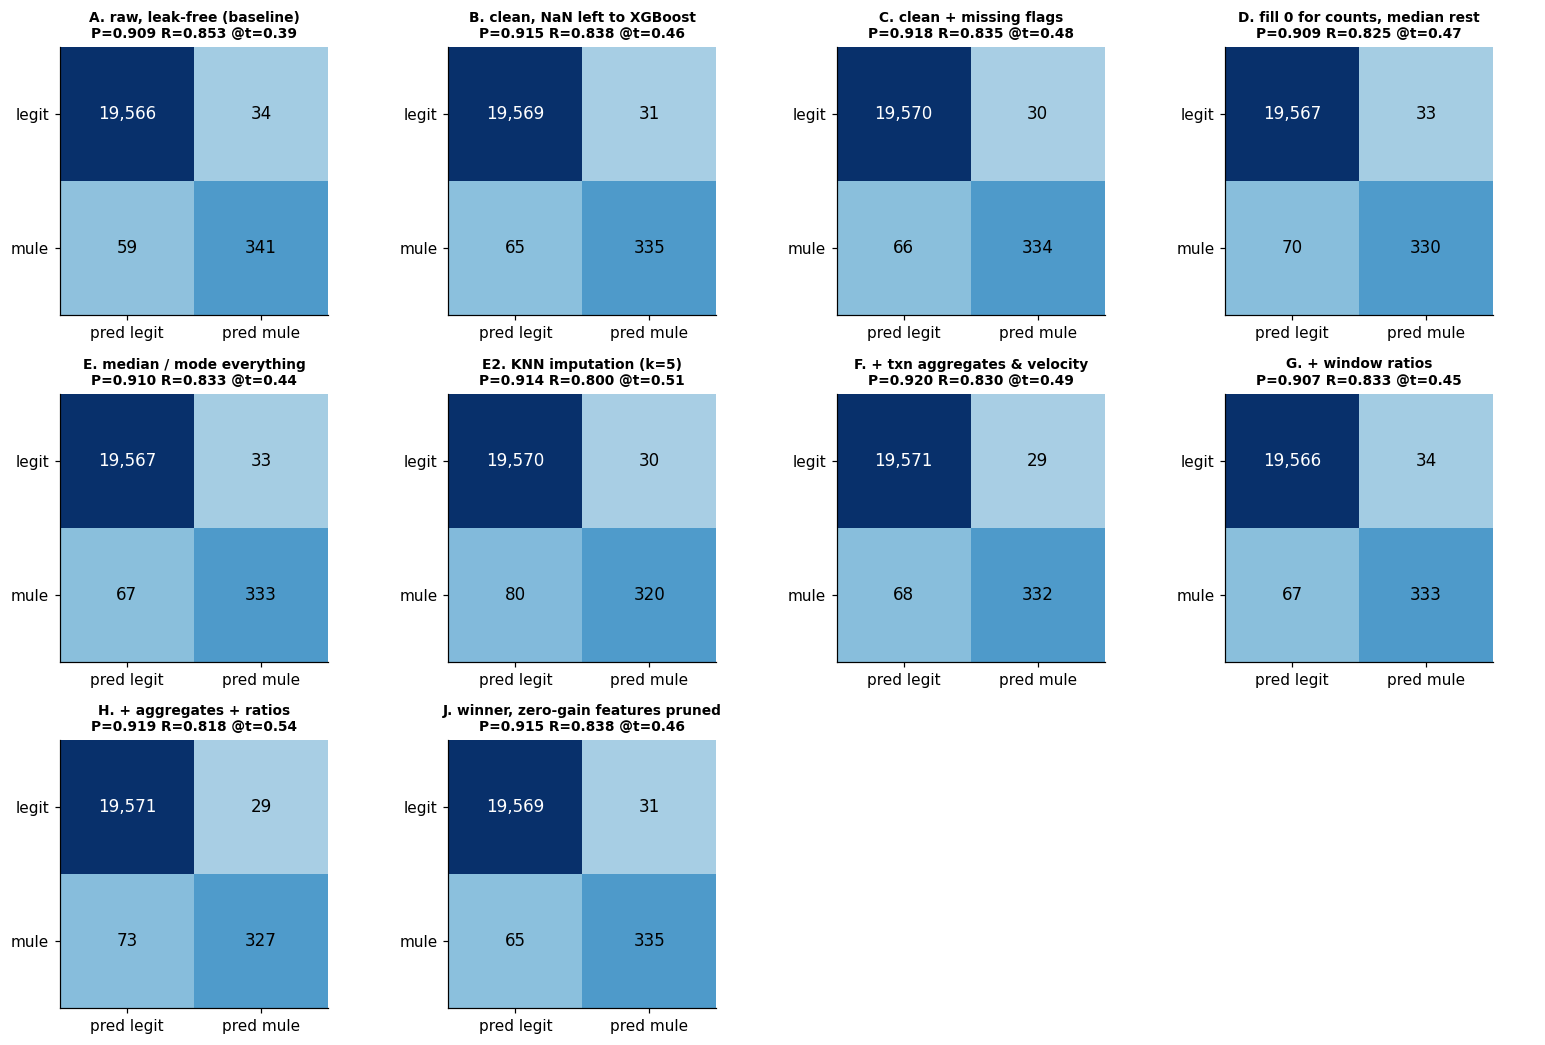

In [11]:
plot_confusions(list(RESULTS))

## 5. Conclusions
| Result | Why | Decision |
|---|---|---|
| **Txn aggregates & velocity (F), window ratios (G), both (H): no gain beyond noise.** Best (H) is 1% better on OOF, inside B's ±1.7% seed-to-seed noise, and 5% *worse* on the holdout | trees already combine the raw window columns with two splits; with only 1,600 training mules, extra derived columns mainly add more ways to overfit | **no engineered features**: they cannot be justified by the evidence |
| Pruning zero-gain features (J) does not change the score (table above) | XGBoost already ignores useless columns | no hard-coded drop list |
| Only the **leaky** counter features ever produced a large FE gain (old notebook, −17% log-loss) | they encode account closure (EDA section 8) | excluded on principle; their cost is quantified in notebook 04 section 7 |

Two more feature families (peer-group-relative activity, activity composition) were tested later with the final model: see **notebook 03b** (no gain).

**Promoted to `src/features.py`:** leak-free cleaning only, NaN left for XGBoost (variant B), 156 features.

In [12]:
X_sel.columns.to_series().to_csv('selected_features.csv', index=False, header=False)
res[cols].to_csv('fe_results.csv')